# 2nd Assignement - Pocket Milling

In [3]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
#import plotly.graph_objects as go
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np

## Machining: pocket milling

`E_PO_REC(4,0,0,"FR2T D10 ALU FSI","",1,0.05,2,150,2,1,15,3,0,-1,90,3,91,1,0,85,90,-35,90,60,30,5,0,0,0,8,3,15,3,0,0,1,2,91);*RO*`

**The follower is just an assumption about the meaning of the .mpf code!**

| Parameter No. | Value                | Meaning                             | Technical interpretation                                                           |
| ------------- | -------------------- | ----------------------------------- | ---------------------------------------------------------------------------------- |
| 1             | `4`                  | Operation type = rectangular pocket | “4” identifies a **rectangular pocket milling** operation in ShopMill event syntax |
| 2–3           | `0,0`                | Internal control flags              | Used by the Siemens interpreter; not relevant for machining logic                  |
| 4             | `"FR2T D10 ALU FSI"` | **Tool name**                       | 2-flute end mill, Ø10 mm, designed for aluminum                                    |
| 5             | `""`                 | Workpiece material (empty)          | Not explicitly defined here                                                        |
| 6             | `1`                  | Activation flag                     | Enables the operation block                                                        |
| 7             | `0.05`               | **Feed per tooth (fz)** [mm/tooth]  | Typical value for aluminum finishing (0.05 mm per tooth)                           |
| 8             | `2`                  | **Number of flutes (z)**            | 2 cutting edges                                                                    |
| 9             | `150`                | **Feedrate (F)** [mm/min]           | Total linear feedrate                                                              |
| 10            | `2`                  | Pass type (roughing/finishing)      | “2” = roughing + finishing sequence                                                |
| 11            | `1`                  | Tool number                         | Likely T1 or T2 in the tool list                                                   |
| 12            | `15`                 | **Total pocket depth** [mm]         | Maximum Z-depth of the pocket (≈ –15 mm)                                           |
| 20–22         | `85, -35, 60`        | **Pocket coordinates (X/Y/Z)**      | Pocket center or corner: approx. X = 85 mm, Y = –35 mm                             |
| 23–24         | `30, 5`              | **Pocket dimensions**               | Length = 60 mm, Width = 30 mm, Step depth = 5 mm                                   |
| 29–32         | `8, 3, 15, 3`        | Step-over and finishing parameters  | Define the number of passes and lateral step distance                              |
| Final         | `1, 2, 91`           | End-of-cycle codes                  | Marks cycle completion and return moves                                            |


**Workpiece dimensions**:
 170x70x20 mm = {X x Y x Z}

**Machining parameters** (in order to evaluate the power and energy):

* tool (outer) diameter $D = 10$ mm
* depth of pass: $a_p = 1$ mm
* feed per tooth $f_z = 0.05$ mm/rev
* number of teeth $z = 2$
* cutting speed $V_c = 150$ m/min

It's possible to derive:

* spindle speed $N = \frac{V_c}{\pi D} \approx 4775$ rpm
* feed rate (feed velocity) $V_f = f_z\,z \, N \approx 477$ mm/min 

In [4]:
D = 10  #(mm)
a_p = 1 #(mm)
fz = 0.05   #(mm/rev)
z = 2
Vc = 150    #m/min
N = Vc/(np.pi * D) * 1000
Vf = fz*z*N

## Tasks

It's required to analyse the power consumption, in particular:

* avg. per revolution
* min/max per revolution
* power profile in function of revolution (read mail)
* energy in one revolution (I suppose the average energy)

In order to do this it important to estimate the active machining operation.

It's needed to distinguish the total power and just the cutting power.

In [5]:
fileSession5A1A = "Analyse Usinage/Session5A1A.csv"
fileSession5A1B = "Analyse Usinage/Session5A1B.csv"

In [6]:
df5A1A = pd.read_csv(fileSession5A1A, skiprows=9)
df5A1B = pd.read_csv(fileSession5A1B, skiprows=9)

In [7]:
# Naming columns
cols = ['time', 'prog_pos_x', 'meas_pos_x', 'power', 'prog_pos_y', 'meas_pos_y','prog_pos_z', 'meas_pos_z', 'niente']
for df in [df5A1A, df5A1B]:
    df.columns = cols

df5A1A = df5A1A.drop('niente', axis=1)
df5A1B = df5A1B.drop('niente', axis=1)

# ora non saprei

<function matplotlib.pyplot.show(close=None, block=None)>

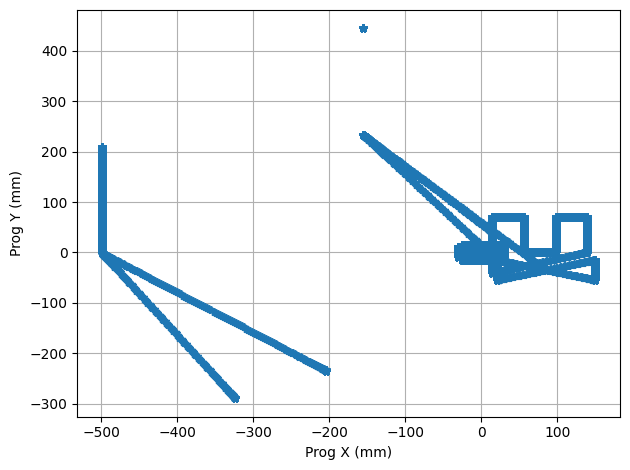

In [8]:
# plot x-y
plt.plot(df5A1A['prog_pos_x'], df5A1A['prog_pos_y'], marker='*', linestyle='none')
plt.xlabel('Prog X (mm)')
plt.ylabel('Prog Y (mm)')
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

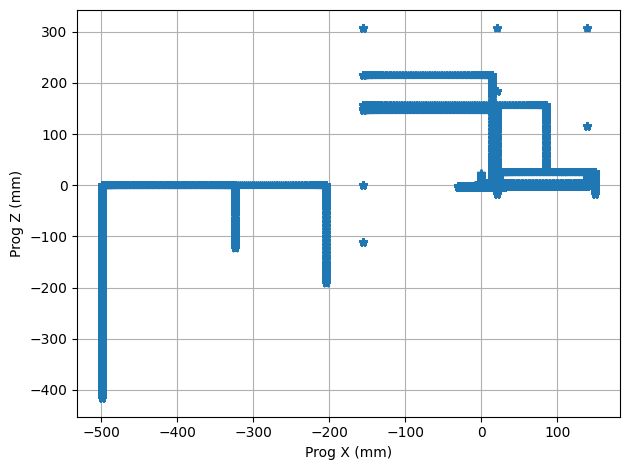

In [9]:
# plot x-z
plt.plot(df5A1A['prog_pos_x'], df5A1A['prog_pos_z'], marker='*', linestyle='none')
plt.xlabel('Prog X (mm)')
plt.ylabel('Prog Z (mm)')
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

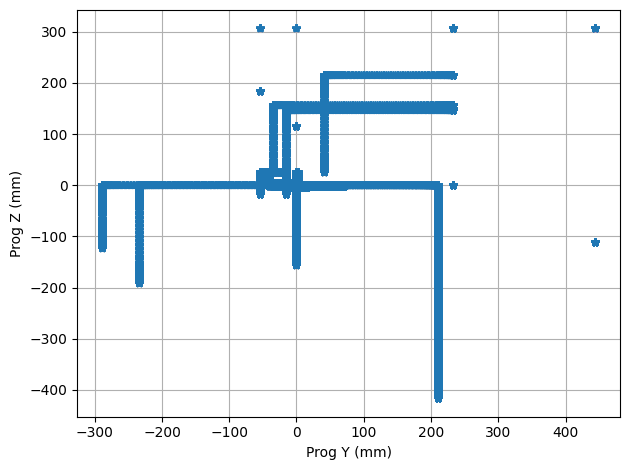

In [10]:
# plot y-z
plt.plot(df5A1A['prog_pos_y'], df5A1A['prog_pos_z'], marker='*', linestyle='none')
plt.xlabel('Prog Y (mm)')
plt.ylabel('Prog Z (mm)')
plt.grid(True)
plt.tight_layout()
plt.show

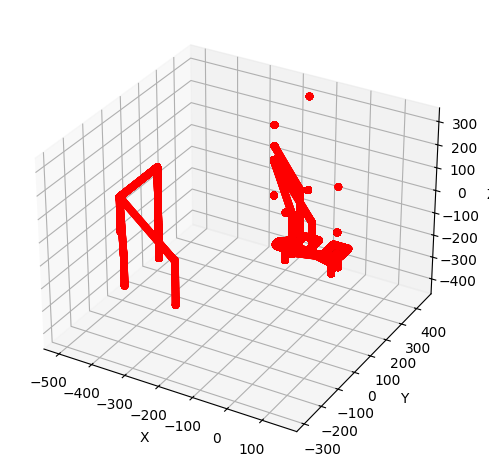

In [11]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(df5A1A['prog_pos_x'], df5A1A['prog_pos_y'], df5A1A['prog_pos_z'], c='r', marker='o')  # scatter 3D

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')


plt.tight_layout()
plt.show()

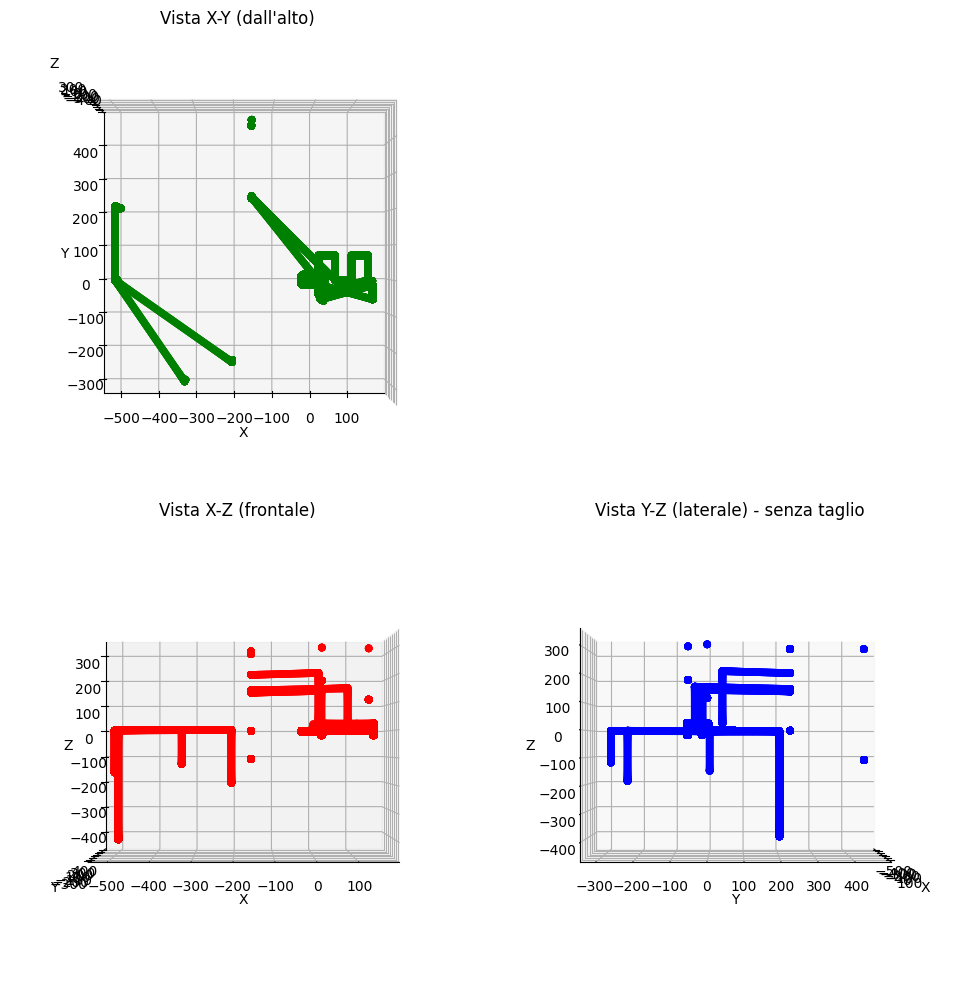

In [17]:
fig = plt.figure(figsize=(10, 10))

# --- Vista X-Y (sopra) ---
ax_top = fig.add_subplot(2, 2, 1, projection='3d')
ax_top.scatter(df5A1A['prog_pos_x'], df5A1A['prog_pos_y'], df5A1A['prog_pos_z'], c='g', marker='o')
ax_top.view_init(elev=90, azim=-90)  # vista dall'alto → piano XY
ax_top.set_title("Vista X-Y (dall'alto)")
ax_top.set_xlabel('X')
ax_top.set_ylabel('Y')
ax_top.set_zlabel('Z')

# --- Vista X-Z (in basso a sinistra) ---
ax1 = fig.add_subplot(2, 2, 3, projection='3d')
ax1.scatter(df5A1A['prog_pos_x'], df5A1A['prog_pos_y'], df5A1A['prog_pos_z'], c='r', marker='o')
ax1.view_init(elev=0, azim=-90)  # vista lungo Y → piano XZ
ax1.set_title("Vista X-Z (frontale)")
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# --- Vista Y-Z (in basso a destra) ---
ax2 = fig.add_subplot(2, 2, 4, projection='3d')
ax2.scatter(df5A1A['prog_pos_x'], df5A1A['prog_pos_y'], df5A1A['prog_pos_z'], c='b', marker='o')
ax2.view_init(elev=0, azim=0)  # vista lungo X → piano YZ
ax2.set_title("Vista Y-Z (laterale) - senza taglio")
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

plt.tight_layout()
plt.show()



potrei filtrare i dati per intersezione della regione di fresatura

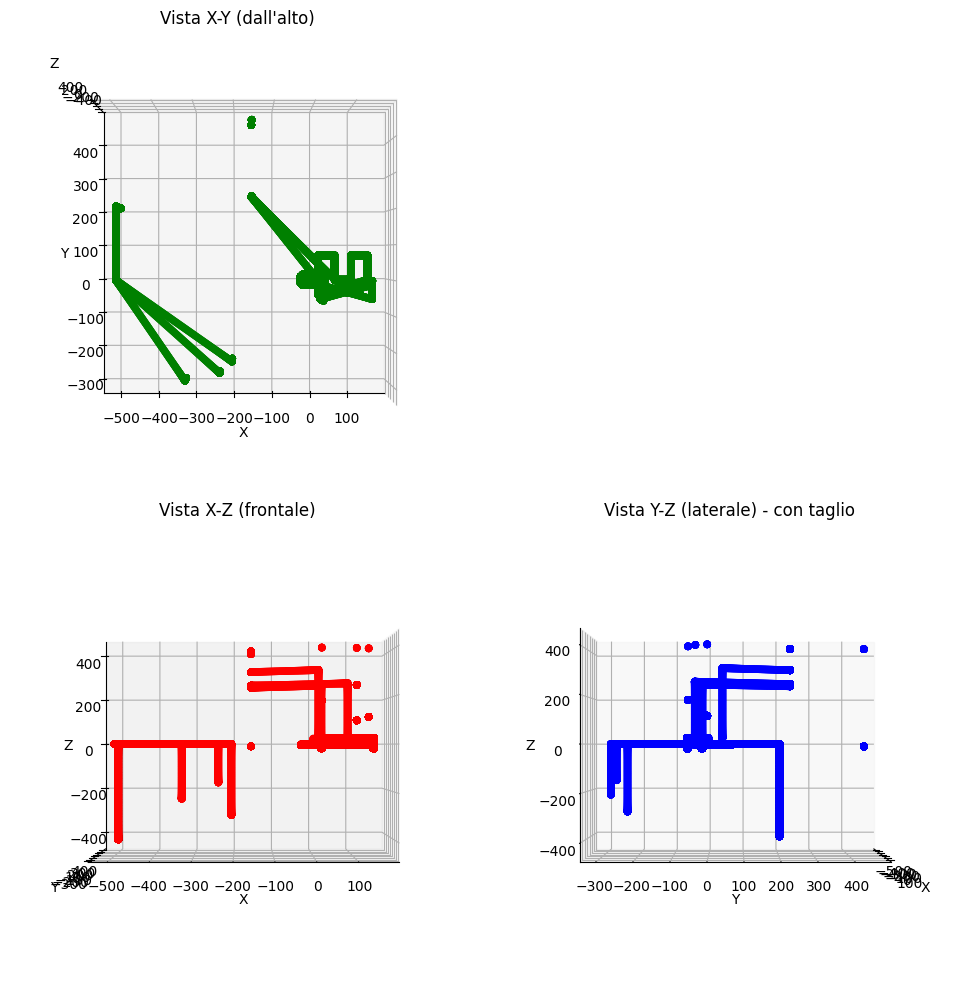

In [18]:
fig = plt.figure(figsize=(10, 10))

# --- Vista X-Y (sopra) ---
ax_top = fig.add_subplot(2, 2, 1, projection='3d')
ax_top.scatter(df5A1B['prog_pos_x'], df5A1B['prog_pos_y'], df5A1B['prog_pos_z'], c='g', marker='o')
ax_top.view_init(elev=90, azim=-90)  # vista dall'alto → piano XY
ax_top.set_title("Vista X-Y (dall'alto)")
ax_top.set_xlabel('X')
ax_top.set_ylabel('Y')
ax_top.set_zlabel('Z')

# --- Vista X-Z (in basso a sinistra) ---
ax1 = fig.add_subplot(2, 2, 3, projection='3d')
ax1.scatter(df5A1B['prog_pos_x'], df5A1B['prog_pos_y'], df5A1B['prog_pos_z'], c='r', marker='o')
ax1.view_init(elev=0, azim=-90)  # vista lungo Y → piano XZ
ax1.set_title("Vista X-Z (frontale)")
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# --- Vista Y-Z (in basso a destra) ---
ax2 = fig.add_subplot(2, 2, 4, projection='3d')
ax2.scatter(df5A1B['prog_pos_x'], df5A1B['prog_pos_y'], df5A1B['prog_pos_z'], c='b', marker='o')
ax2.view_init(elev=0, azim=0)  # vista lungo X → piano YZ
ax2.set_title("Vista Y-Z (laterale) - con taglio")
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

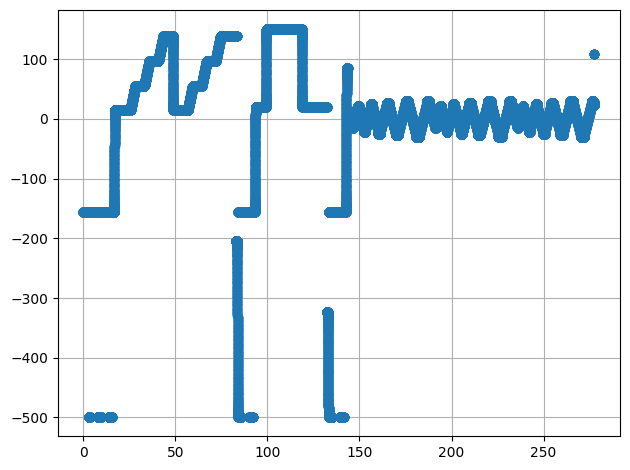

In [12]:
# plot t-x
plt.plot(df5A1A['time'], df5A1A['prog_pos_x'], marker='o', linestyle='none')
plt.grid(True)
plt.tight_layout()
plt.show